In [2]:
!pip install torch torchvision
!pip install nibabel          # for reading .nii.gz files
!pip install monai            # medical imaging deep learning library
!pip install nilearn          # for visualization
!pip install matplotlib numpy scipy
!pip install segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 16.9 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 3.4 MB/s eta 0:00:0000:01


In [3]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split

# Base paths
TRAIN_DIR = Path("/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData")
VAL_DIR   = Path("/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData")
SAVE_DIR  = Path("/kaggle/working")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Training patients: {len(list(TRAIN_DIR.glob('BraTS20_Training_*')))}")
print(f"Validation patients: {len(list(VAL_DIR.glob('BraTS20_Validation_*')))}")

Device: cuda
Training patients: 0
Validation patients: 0


In [4]:
class CachedBraTS(Dataset):
    def __init__(self, names, cache):
        self.cache, self.index = Path(cache), []
        for n in names:
            y = np.load(self.cache / f"{n}_y.npy", mmap_mode="r")
            self.index += [(n, i) for i in range(len(y))]
    def __len__(self): return len(self.index)
    def __getitem__(self, k):
        n, i = self.index[k]
        x = np.load(self.cache / f"{n}_x.npy", mmap_mode="r")[i].astype(np.float32)
        y = np.load(self.cache / f"{n}_y.npy", mmap_mode="r")[i]
        masks = np.stack([y > 0, (y == 1) | (y == 3), y == 3]).astype(np.float32)
        return torch.from_numpy(x), torch.from_numpy(masks)

CACHE = next(Path("/kaggle/input").rglob("*_x.npy")).parent
print("Cache found at:", CACHE)
names = sorted(p.stem[:-2] for p in CACHE.glob("*_x.npy"))
train_names, val_names = train_test_split(names, test_size=0.2, random_state=42)

train_ds, val_ds = CachedBraTS(train_names, CACHE), CachedBraTS(val_names, CACHE)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2,
                          pin_memory=True, persistent_workers=True)
val_loader   = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2,
                          pin_memory=True, persistent_workers=True)

Cache found at: /kaggle/input/datasets/iahmedpy/brats-cache/brats_cache


In [ ]:
# U-Net with 4-channel input, 3 output classes
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=4,
    classes=3,
    activation=None
)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total_params:,}")

Model parameters: 24,439,795


In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        preds_f  = preds.view(-1)
        targets_f = targets.view(-1)
        intersection = (preds_f * targets_f).sum()
        return 1 - (2 * intersection + self.smooth) / \
                   (preds_f.sum() + targets_f.sum() + self.smooth)

class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.5, bce_weight=0.5):
        super().__init__()
        self.dice = DiceLoss()
        self.bce  = nn.BCEWithLogitsLoss()
        self.dw   = dice_weight
        self.bw   = bce_weight

    def forward(self, preds, targets):
        return self.dw * self.dice(preds, targets) + \
               self.bw * self.bce(preds, targets)

def dice_per_region(preds, targets, threshold=0.5):
    """Returns [WT_dice, TC_dice, ET_dice]"""
    preds = (torch.sigmoid(preds) > threshold).float()
    smooth = 1e-6
    scores = []
    for i in range(preds.shape[1]):
        p = preds[:, i].reshape(-1)
        t = targets[:, i].reshape(-1)
        inter = (p * t).sum()
        scores.append(((2 * inter + smooth) / (p.sum() + t.sum() + smooth)).item())
    return scores  # [WT, TC, ET]

criterion = CombinedLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

In [ ]:
CKPT_DIR = Path("/kaggle/working/ckpt"); CKPT_DIR.mkdir(exist_ok=True)
NUM_EPOCHS = 50

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
scaler    = torch.amp.GradScaler("cuda")

def save_ckpt(path, **state):
    tmp = path.with_suffix(".tmp")
    torch.save(state, tmp)
    os.replace(tmp, path)
    
import shutil
old = next(Path("/kaggle/input").rglob("last.pth"), None)
if old: shutil.copy(old, CKPT_DIR / "last.pth")
# ---- resume ----
start_epoch, best_dice = 1, 0.0
history = {"train_loss": [], "val_loss": [], "wt": [], "tc": [], "et": [], "mean": []}
if (CKPT_DIR / "last.pth").exists():
    ck = torch.load(CKPT_DIR / "last.pth", map_location=device, weights_only=False)
    model.load_state_dict(ck["model"]);         optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, best_dice, history = ck["epoch"] + 1, ck["best_dice"], ck["history"]
    print(f"Resumed from epoch {ck['epoch']} (best Dice {best_dice:.4f})")

# ---- train ----
for epoch in range(start_epoch, NUM_EPOCHS + 1):
    model.train(); tl = 0.0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x)
        loss = criterion(out.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update()
        tl += loss.item()
    tl /= len(train_loader)

    model.eval(); vl = 0.0; sc = []
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(x)
            out = out.float()
            vl += criterion(out, y).item()
            sc.append(dice_per_region(out, y))
    vl /= len(val_loader)
    wt, tc, et = np.mean(sc, axis=0).tolist()
    mean = (wt + tc + et) / 3
    scheduler.step()

    for k, v in zip(history, [tl, vl, wt, tc, et, mean]): history[k].append(float(v))
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | train {tl:.4f} | val {vl:.4f} | "
          f"WT {wt:.4f} TC {tc:.4f} ET {et:.4f} | mean {mean:.4f}")

    if mean > best_dice:
        best_dice = mean
        save_ckpt(CKPT_DIR / "best.pth", model=model.state_dict(), epoch=epoch,
                  dice={"wt": wt, "tc": tc, "et": et, "mean": mean})
        print("  ✓ new best")

    save_ckpt(CKPT_DIR / "last.pth", model=model.state_dict(), optimizer=optimizer.state_dict(),
              scheduler=scheduler.state_dict(), scaler=scaler.state_dict(),
              epoch=epoch, best_dice=best_dice, history=history)

Epoch 01/50 | train 0.3265 | val 0.1379 | WT 0.8684 TC 0.7154 ET 0.6887 | mean 0.7575
  ✓ new best
Epoch 02/50 | train 0.0662 | val 0.1069 | WT 0.8740 TC 0.6910 ET 0.7010 | mean 0.7553
Epoch 03/50 | train 0.0475 | val 0.1061 | WT 0.8684 TC 0.6840 ET 0.6667 | mean 0.7397
Epoch 04/50 | train 0.0405 | val 0.0952 | WT 0.8852 TC 0.7049 ET 0.6838 | mean 0.7579
  ✓ new best
Epoch 05/50 | train 0.0366 | val 0.0959 | WT 0.8796 TC 0.7230 ET 0.7052 | mean 0.7693
  ✓ new best
Epoch 06/50 | train 0.0335 | val 0.0968 | WT 0.8816 TC 0.7108 ET 0.6967 | mean 0.7630
Epoch 07/50 | train 0.0317 | val 0.1091 | WT 0.8677 TC 0.6578 ET 0.6562 | mean 0.7272
Epoch 08/50 | train 0.0304 | val 0.0974 | WT 0.8804 TC 0.7149 ET 0.6743 | mean 0.7565
Epoch 09/50 | train 0.0286 | val 0.0965 | WT 0.8841 TC 0.7074 ET 0.6972 | mean 0.7629
Epoch 10/50 | train 0.0275 | val 0.0959 | WT 0.8817 TC 0.7128 ET 0.6947 | mean 0.7631
Epoch 11/50 | train 0.0266 | val 0.0970 | WT 0.8822 TC 0.7186 ET 0.7013 | mean 0.7674
Epoch 12/50 | t

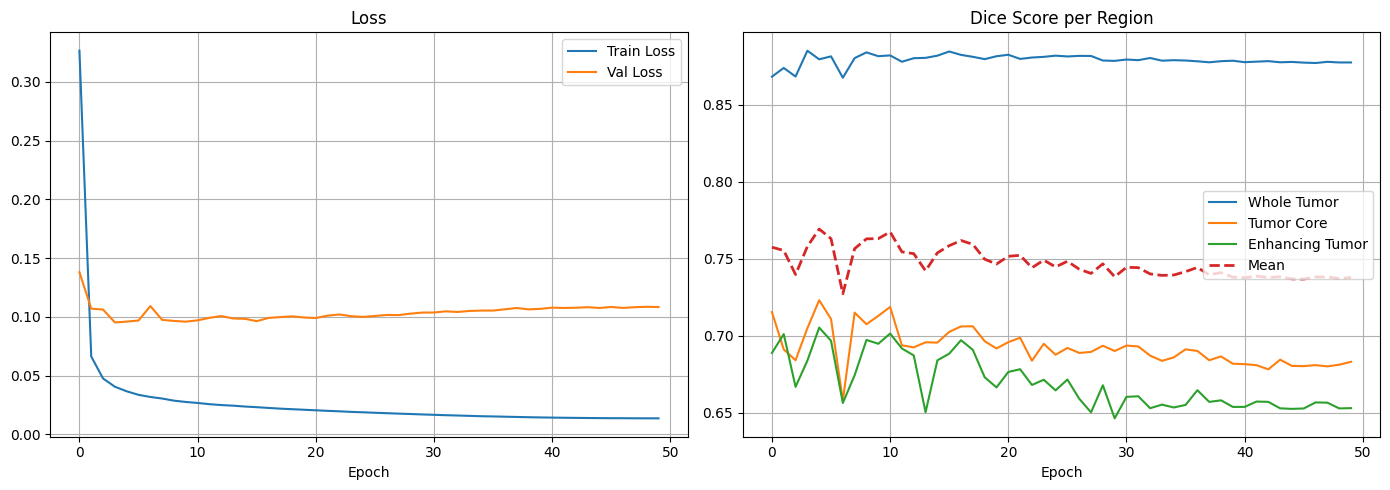

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"],   label="Val Loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["wt"],   label="Whole Tumor")
axes[1].plot(history["tc"],   label="Tumor Core")
axes[1].plot(history["et"],   label="Enhancing Tumor")
axes[1].plot(history["mean"], label="Mean", linestyle="--", linewidth=2)
axes[1].set_title("Dice Score per Region")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(SAVE_DIR / "training_curves.png", dpi=100)
plt.show()

Best: epoch 5 | WT 0.8796 | TC 0.7230 | ET 0.7052 | mean 0.7693


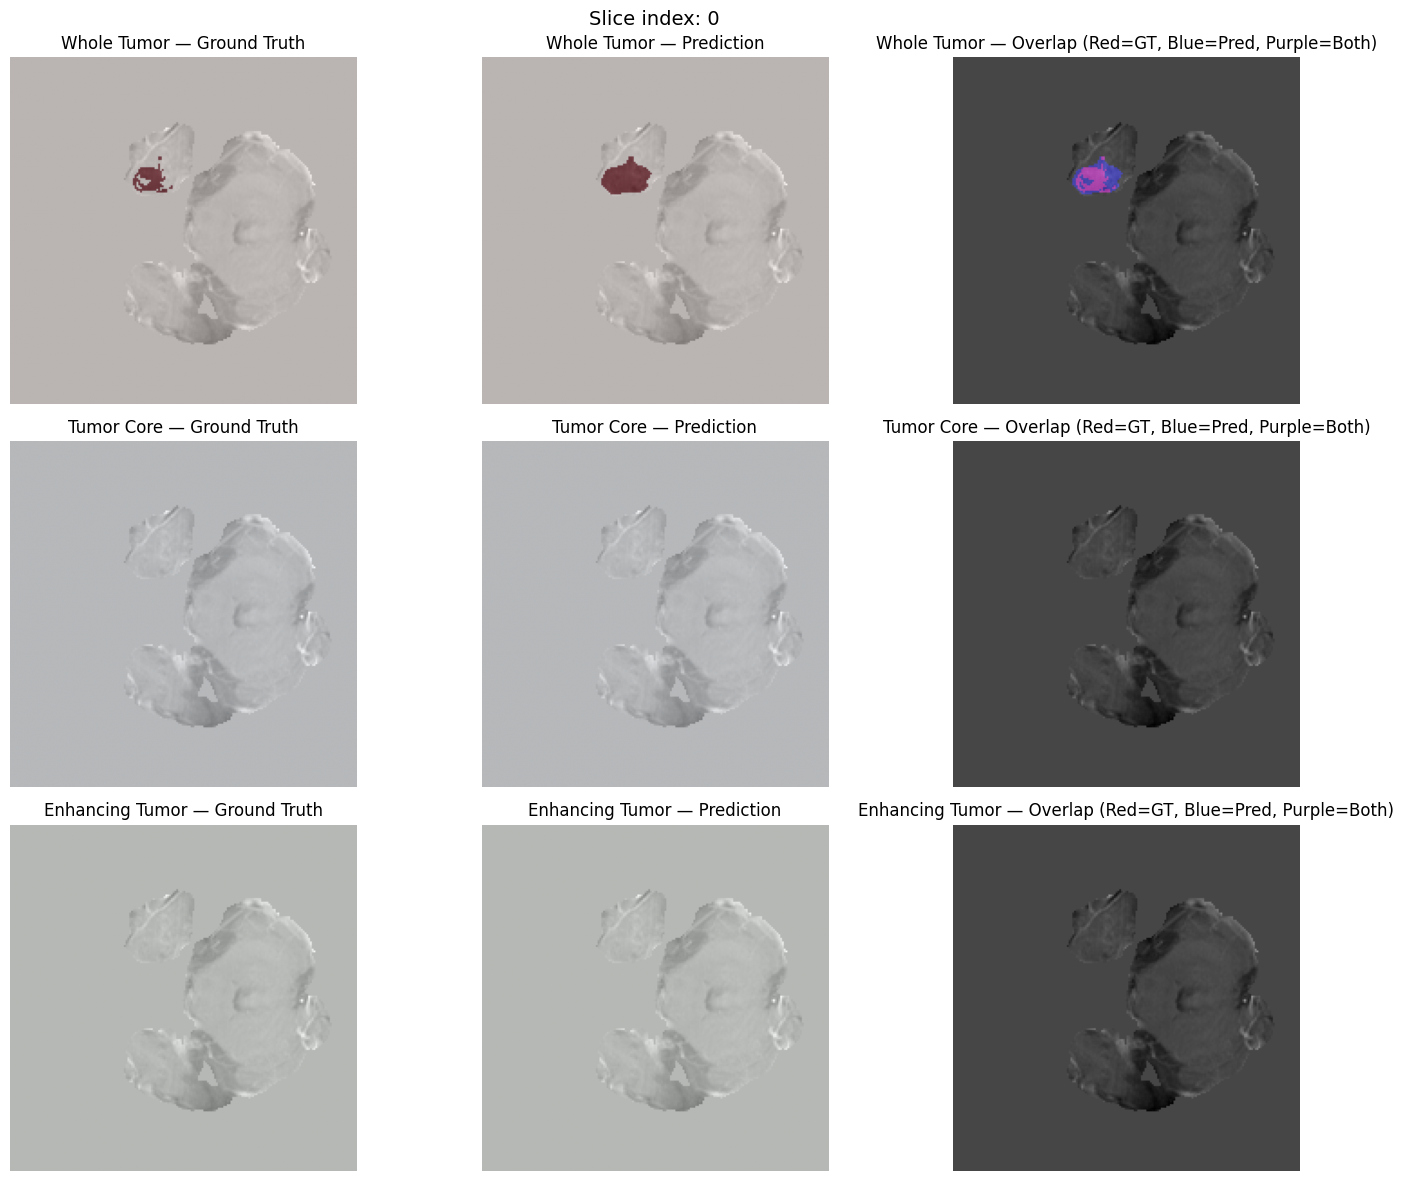

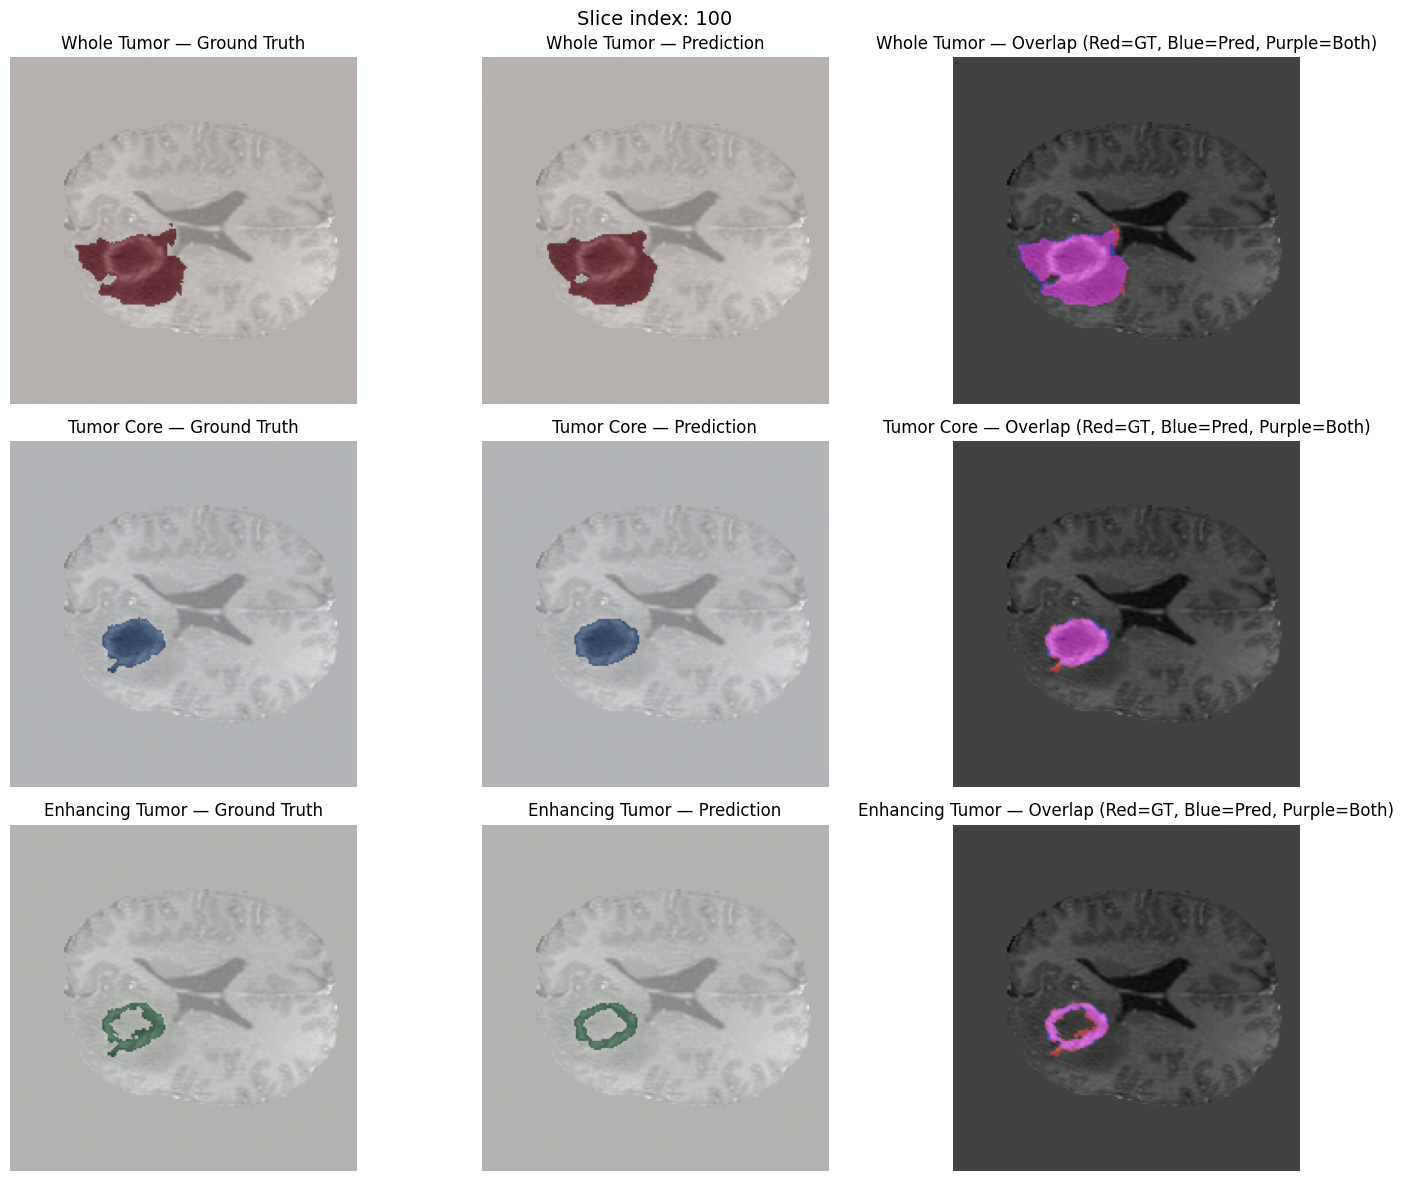

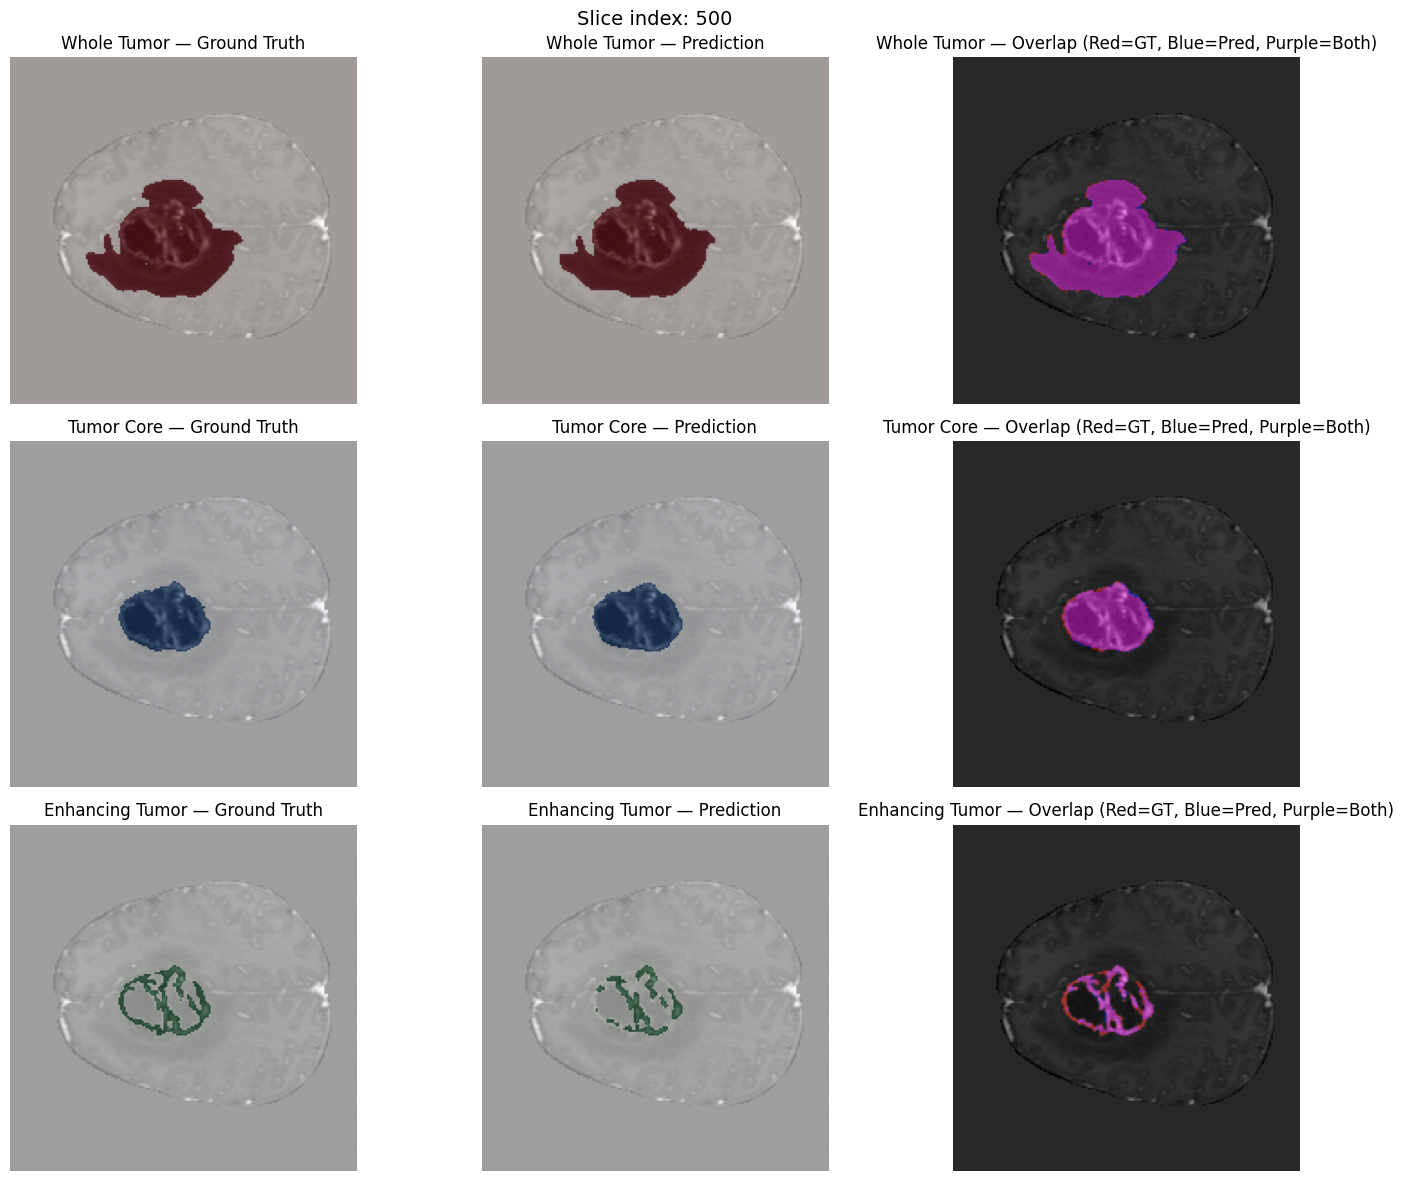

In [ ]:
def visualize_predictions(model, dataset, indices, device, save_path=None):
    model.eval()
    region_names = ["Whole Tumor", "Tumor Core", "Enhancing Tumor"]
    colors       = ["Reds", "Blues", "Greens"]

    for idx in indices:
        image, mask = dataset[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(image.unsqueeze(0).to(device)))
            pred = (pred > 0.5).float().cpu().squeeze(0)

        bg = image[1].numpy()

        fig, axes = plt.subplots(3, 3, figsize=(15, 12))
        for i, (region, cmap) in enumerate(zip(region_names, colors)):
            axes[i][0].imshow(bg, cmap="gray")
            axes[i][0].imshow(mask[i].numpy(), alpha=0.5, cmap=cmap)
            axes[i][0].set_title(f"{region} — Ground Truth")
            axes[i][0].axis("off")

            axes[i][1].imshow(bg, cmap="gray")
            axes[i][1].imshow(pred[i].numpy(), alpha=0.5, cmap=cmap)
            axes[i][1].set_title(f"{region} — Prediction")
            axes[i][1].axis("off")

            overlap = np.zeros((*bg.shape, 3))
            overlap[mask[i].numpy() > 0]   = [1, 0, 0]  # GT = red
            overlap[pred[i].numpy() > 0.5] = [0, 0, 1]  # Pred = blue
            # Overlap = purple
            gt_arr   = mask[i].numpy() > 0
            pred_arr = pred[i].numpy() > 0.5
            overlap[gt_arr & pred_arr] = [1, 0, 1]

            axes[i][2].imshow(bg, cmap="gray")
            axes[i][2].imshow(overlap, alpha=0.4)
            axes[i][2].set_title(f"{region} — Overlap (Red=GT, Blue=Pred, Purple=Both)")
            axes[i][2].axis("off")

        plt.suptitle(f"Slice index: {idx}", fontsize=14)
        plt.tight_layout()
        if save_path:
            plt.savefig(save_path / f"prediction_{idx}.png", dpi=100)
        plt.show()

ck = torch.load(CKPT_DIR / "best.pth", map_location=device, weights_only=False)
model.load_state_dict(ck["model"])
d = ck["dice"]
print(f"Best: epoch {ck['epoch']} | WT {d['wt']:.4f} | TC {d['tc']:.4f} | ET {d['et']:.4f} | mean {d['mean']:.4f}")

visualize_predictions(model, val_ds, indices=[0, 100, 500],
                      device=device, save_path=SAVE_DIR)